# 03 – Gaussian Naive Bayes (Agischa)
**TBP Data Mining – Early Warning System Kelulusan Mahasiswa**

Notebook ini melatih model **Gaussian Naive Bayes** memakai dataset bersama hasil preprocessing (split 80:20, `random_state=42`, stratify), lalu mengevaluasinya pada data test.

**Label target:** `0 = Dropout`, `1 = Graduate`.
Karena tujuan sistem adalah *early warning* (mendeteksi mahasiswa berisiko **Dropout**), metrik Precision, Recall, dan F1 dihitung untuk **kelas Dropout (label 0)** sebagai kelas yang diwaspadai.

**Output** disimpan ke `models/bayes/`:
- `model_naive_bayes.pkl` – model terlatih
- `prediksi_naive_bayes.csv` – `y_true`, `y_pred`, `y_proba_dropout`, `y_proba_graduate`
- `metrics_naive_bayes.json` – metrik evaluasi + waktu training
- grafik confusion matrix, ROC curve, distribusi probabilitas

## 1. Konsep singkat Gaussian Naive Bayes
Naive Bayes memakai **Teorema Bayes** untuk menghitung peluang seorang mahasiswa masuk kelas tertentu berdasarkan fiturnya:

$$P(\text{Dropout} \mid \text{fitur}) \propto P(\text{Dropout}) \times P(\text{IPK} \mid \text{Dropout}) \times P(\text{IPS} \mid \text{Dropout}) \times \dots$$

- **Naive** → model *mengasumsikan* setiap fitur saling independen jika kelasnya diketahui, sehingga peluangnya cukup dikalikan.
- **Gaussian** → peluang tiap fitur dihitung dengan kurva normal (lonceng). Saat training model hanya menghitung **rata-rata dan varians setiap fitur per kelas**, jadi sangat cepat.
- Prediksi = kelas dengan peluang terbesar.
- **Tidak perlu scaling**, karena tiap fitur dimodelkan dengan mean dan variansnya sendiri.

## 2. Import library
| Library | Fungsi |
|---|---|
| `pandas` | membaca CSV dan mengolah tabel |
| `time` | mengukur waktu training |
| `json`, `pathlib` | menyimpan metrik & mengatur folder |
| `matplotlib`, `seaborn` | membuat grafik |
| `joblib` | menyimpan model ke file `.pkl` |
| `sklearn.naive_bayes.GaussianNB` | algoritma Gaussian Naive Bayes |
| `sklearn.metrics` | menghitung metrik evaluasi |

In [1]:
import json
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay)

## 3. Atur lokasi folder
- `DATA_DIR` = folder berisi `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv`.
- `MODEL_DIR` = tempat menyimpan model dan hasil (`models/bayes`).

Sel di bawah mencari folder data secara otomatis di beberapa lokasi umum. **Jika tidak ketemu, ganti `DATA_DIR` secara manual** sesuai struktur repo tim.

In [2]:
KANDIDAT_DATA = [Path("data"), Path("../data"), Path("data/processed"), Path("../data/processed"),
                 Path("output"), Path("../output"), Path(".")]
DATA_DIR = next((p for p in KANDIDAT_DATA if (p / "X_train.csv").exists()), None)
assert DATA_DIR is not None, "X_train.csv tidak ditemukan. Isi DATA_DIR secara manual."

# models/ diletakkan di root repo (satu tingkat di atas jika notebook ada di folder notebooks/)
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
MODEL_DIR = ROOT / "models" / "bayes"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

LABELS = ["Dropout", "Graduate"]   # urutan sesuai label 0 dan 1
print("Folder data :", DATA_DIR)
print("Folder model:", MODEL_DIR)

Folder data : ../data
Folder model: ../models/bayes


## 4. Membaca data train dan test
`.squeeze()` mengubah tabel berisi 1 kolom menjadi *Series* (deret) agar bisa langsung dipakai sebagai target.

**Contoh output yang diharapkan:** `X_train: (80000, 9)`, `X_test: (20000, 9)`, dan proporsi kelas sekitar 50:50.

In [3]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test  = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test  = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporsi y_train:", y_train.value_counts(normalize=True).round(4).to_dict())
print("Proporsi y_test :", y_test.value_counts(normalize=True).round(4).to_dict())
X_train.head()

X_train: (80000, 9) | X_test: (20000, 9)
Proporsi y_train: {0: 0.5004, 1: 0.4996}
Proporsi y_test : {0: 0.5004, 1: 0.4996}


,IPK,Mata Kuliah Tidak Lulus,Jumlah Cuti Akademik,Pekerjaan Sambil Kuliah,Jumlah Semester,IPS Rata-rata,IPS Semester Akhir,IPS Tren,Kategori Kehadiran
0,2.65,2,1,0,8,2.898750,2.53,-0.07,2
1,3.36,2,1,1,13,3.036154,3.47,0.51,1
2,2.59,2,2,1,7,2.557143,2.42,-0.88,0
3,3.59,3,1,1,8,3.011250,2.79,-1.14,0
4,3.11,0,0,1,7,3.422857,3.59,0.71,0


## 5. Melatih model + mengukur waktu training
- `GaussianNB()` memakai parameter default (`var_smoothing=1e-9`, nilai kecil yang ditambahkan ke varians agar tidak terjadi pembagian dengan nol).
- `time.perf_counter()` dicatat sebelum dan sesudah `fit()`; selisihnya = waktu training.
- Model **hanya** di-fit pada data train, sehingga tidak ada data leakage.

Waktu training bisa sedikit berbeda di setiap komputer (biasanya < 0,1 detik).

In [4]:
model = GaussianNB()

t0 = time.perf_counter()
model.fit(X_train, y_train)
train_time = time.perf_counter() - t0

print(f"Waktu training: {train_time:.4f} detik")
print("Kelas yang dipelajari:", model.classes_)

Waktu training: 0.0389 detik
Kelas yang dipelajari: [0 1]


## 6. Melihat apa yang dipelajari model
Gaussian NB menyimpan **rata-rata** (`theta_`) setiap fitur per kelas. Jika rata-rata kelas Dropout dan Graduate mirip, model sulit membedakan keduanya.

In [5]:
rata_rata = pd.DataFrame(model.theta_, index=LABELS, columns=X_train.columns).T
rata_rata["selisih"] = rata_rata["Graduate"] - rata_rata["Dropout"]
rata_rata.round(4)

,Dropout,Graduate,selisih
IPK,2.9990,2.9967,-0.0022
Mata Kuliah Tidak Lulus,2.4937,2.5136,0.0199
Jumlah Cuti Akademik,0.9988,1.0007,0.0019
Pekerjaan Sambil Kuliah,0.4986,0.5014,0.0028
Jumlah Semester,10.4955,10.5081,0.0126
IPS Rata-rata,3.0014,3.0007,-0.0008
IPS Semester Akhir,2.9981,2.9981,0.0001
IPS Tren,-0.0026,-0.0041,-0.0015
Kategori Kehadiran,0.8921,0.9007,0.0086


## 7. Prediksi pada data test
- `predict()` → kelas 0/1.
- `predict_proba()` → peluang tiap kelas. Kolom ke-0 = peluang **Dropout**, kolom ke-1 = peluang **Graduate**.

In [6]:
y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)
y_proba_dropout = proba[:, 0]
y_proba_graduate = proba[:, 1]

hasil = pd.DataFrame({
    "y_true": y_test,
    "y_pred": y_pred,
    "y_proba_dropout": y_proba_dropout,
    "y_proba_graduate": y_proba_graduate,
})
hasil["label_asli"] = hasil["y_true"].map({0: "Dropout", 1: "Graduate"})
hasil["label_prediksi"] = hasil["y_pred"].map({0: "Dropout", 1: "Graduate"})
hasil.head(10)

,y_true,y_pred,y_proba_dropout,y_proba_graduate,label_asli,label_prediksi
0,1,1,0.496850,0.503150,Graduate,Graduate
1,0,1,0.497262,0.502738,Dropout,Graduate
2,0,0,0.506668,0.493332,Dropout,Dropout
3,1,0,0.501032,0.498968,Graduate,Dropout
4,0,1,0.494810,0.505190,Dropout,Graduate
5,0,0,0.503989,0.496011,Dropout,Dropout
6,0,1,0.490851,0.509149,Dropout,Graduate
7,0,0,0.503598,0.496402,Dropout,Dropout
8,0,1,0.497297,0.502703,Dropout,Graduate
9,1,1,0.496756,0.503244,Graduate,Graduate


## 8. Metrik evaluasi
| Metrik | Arti (kelas Dropout sebagai fokus) |
|---|---|
| **Accuracy** | persentase seluruh prediksi yang benar |
| **Precision Dropout** | dari mahasiswa yang *diprediksi* Dropout, berapa persen yang benar-benar Dropout |
| **Recall Dropout** | dari mahasiswa yang *benar-benar* Dropout, berapa persen yang berhasil terdeteksi (paling penting untuk early warning) |
| **F1-Score Dropout** | rata-rata harmonis Precision dan Recall |
| **ROC-AUC** | kemampuan model mengurutkan mahasiswa berisiko; 0,5 = tebakan acak, 1,0 = sempurna |
| **Waktu Training** | lama proses `fit()` dalam detik |

`pos_label=0` artinya kelas Dropout (label 0) dianggap kelas positif.

In [7]:
metrics = {
    "model": "Naive Bayes",
    "anggota": "Agischa",
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_dropout": precision_score(y_test, y_pred, pos_label=0),
    "recall_dropout": recall_score(y_test, y_pred, pos_label=0),
    "f1_dropout": f1_score(y_test, y_pred, pos_label=0),
    "roc_auc": roc_auc_score((y_test == 0).astype(int), y_proba_dropout),
    "train_time_sec": train_time,
}
pd.Series(metrics).to_frame("nilai")

,nilai
model,Naive Bayes
anggota,Agischa
accuracy,0.50455
precision_dropout,0.504586
recall_dropout,0.544165
f1_dropout,0.523629
roc_auc,0.505595
train_time_sec,0.038885


## 9. Classification report
Menampilkan Precision, Recall, dan F1 untuk **kedua** kelas, plus `support` (jumlah data asli per kelas).

In [8]:
report = classification_report(y_test, y_pred, target_names=LABELS, digits=4)
print(report)

              precision    recall  f1-score   support

     Dropout     0.5046    0.5442    0.5236     10008
    Graduate     0.5045    0.4649    0.4839      9992

    accuracy                         0.5046     20000
   macro avg     0.5045    0.5045    0.5038     20000
weighted avg     0.5045    0.5046    0.5038     20000



## 10. Confusion matrix
Baris = label asli, kolom = prediksi. Diagonal (kiri atas & kanan bawah) = prediksi benar.

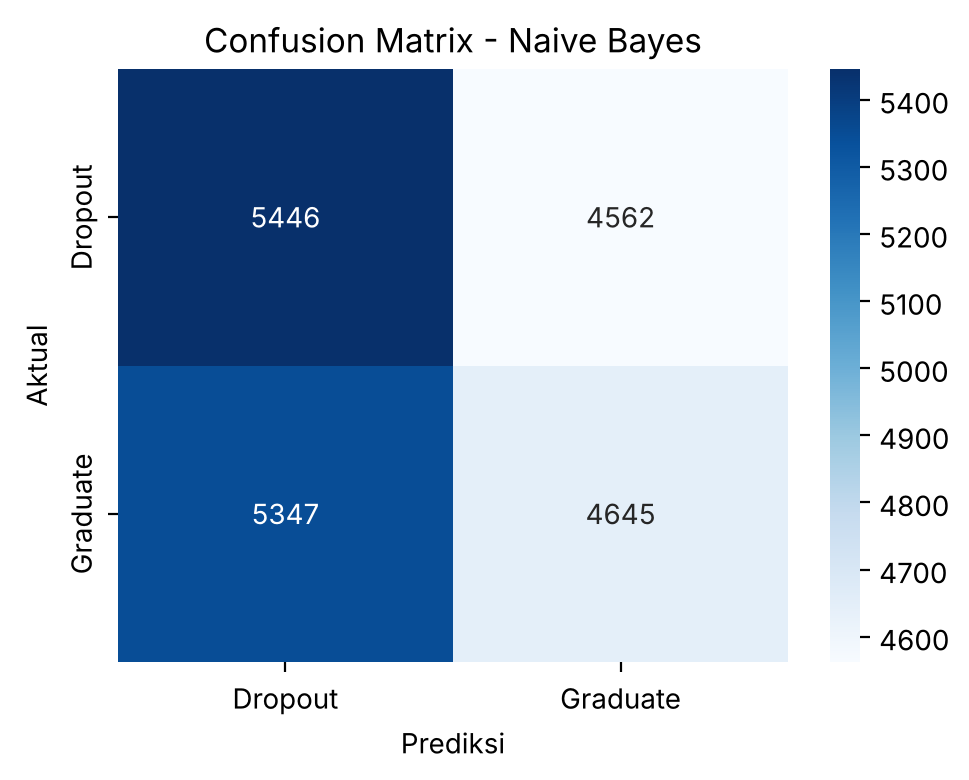

In [9]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title("Confusion Matrix - Naive Bayes")
plt.tight_layout()
plt.savefig(MODEL_DIR / "confusion_matrix_nb.png", dpi=120)
plt.show()

## 11. ROC curve
Garis putus-putus diagonal = tebakan acak (AUC 0,5). Makin jauh kurva model di atas garis itu, makin baik.

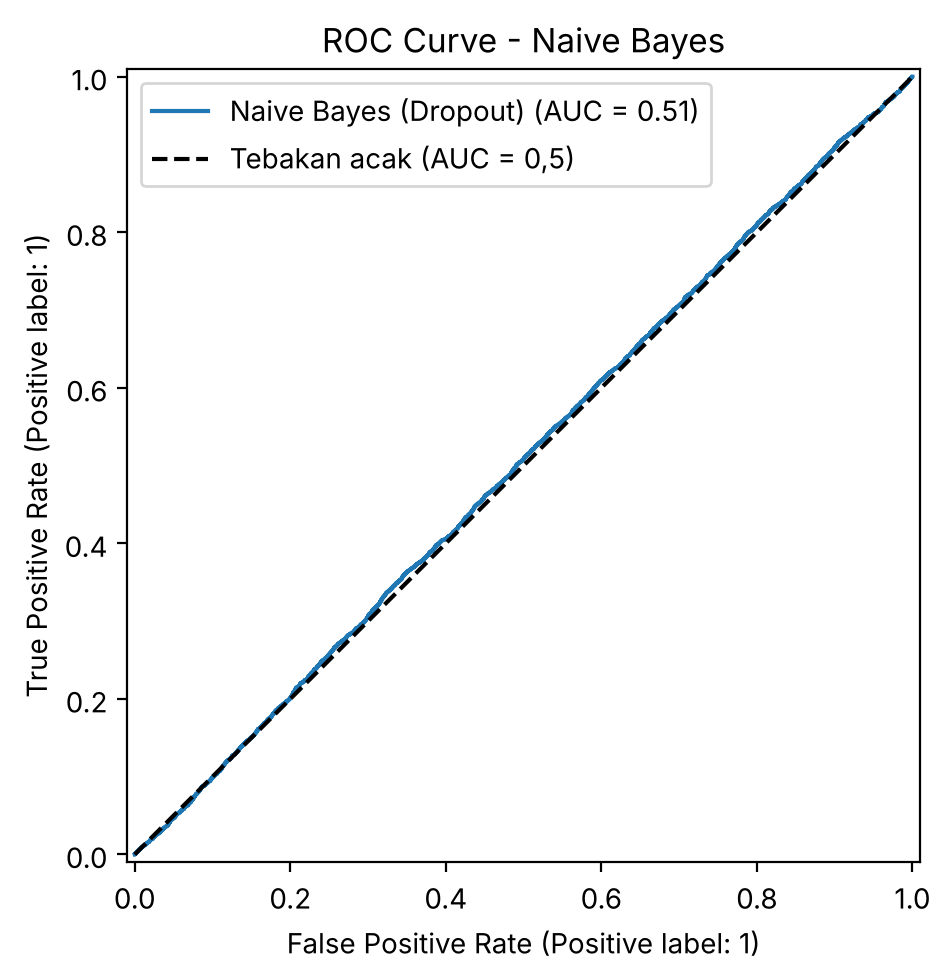

In [10]:
fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions((y_test == 0).astype(int), y_proba_dropout,
                                 name="Naive Bayes (Dropout)", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Tebakan acak (AUC = 0,5)")
ax.legend(); ax.set_title("ROC Curve - Naive Bayes")
plt.tight_layout()
plt.savefig(MODEL_DIR / "roc_curve_nb.png", dpi=120)
plt.show()

## 12. Distribusi probabilitas prediksi
Grafik ini menunjukkan seberapa *yakin* model. Jika kedua warna saling terpisah, model bisa membedakan kelas. Jika saling menutupi dan menumpuk di sekitar 0,5, model ragu.

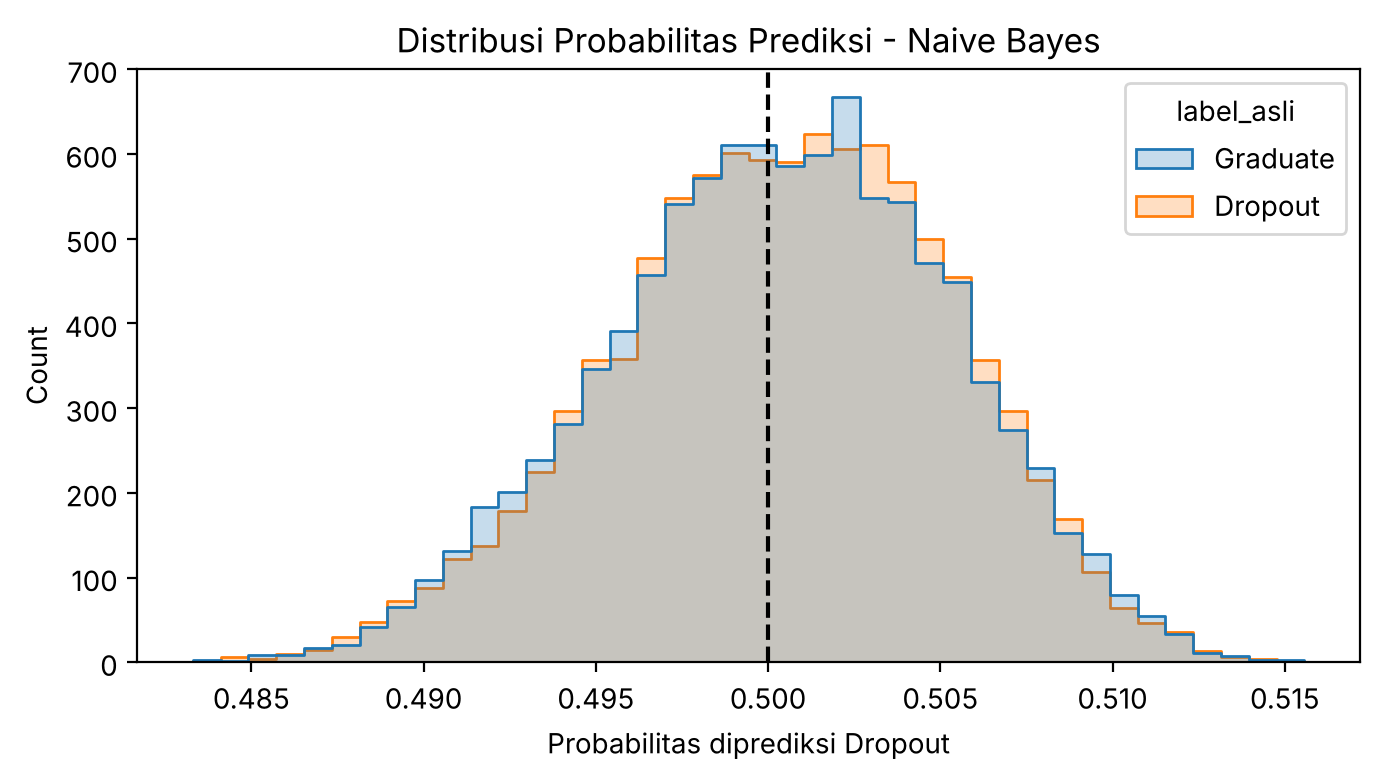

Rentang probabilitas Dropout: 0.4833 - 0.5156


In [11]:
plt.figure(figsize=(7, 4))
sns.histplot(data=hasil, x="y_proba_dropout", hue="label_asli", bins=40, element="step")
plt.axvline(0.5, color="k", ls="--")
plt.xlabel("Probabilitas diprediksi Dropout")
plt.title("Distribusi Probabilitas Prediksi - Naive Bayes")
plt.tight_layout()
plt.savefig(MODEL_DIR / "distribusi_probabilitas_nb.png", dpi=120)
plt.show()
print("Rentang probabilitas Dropout:", round(y_proba_dropout.min(), 4), "-", round(y_proba_dropout.max(), 4))

## 13. Menyimpan model dan hasil ke `models/bayes/`
File ini dipakai untuk benchmark lima algoritma nanti.

In [12]:
joblib.dump(model, MODEL_DIR / "model_naive_bayes.pkl")
hasil[["y_true", "y_pred", "y_proba_dropout", "y_proba_graduate"]].to_csv(
    MODEL_DIR / "prediksi_naive_bayes.csv", index=False)
(MODEL_DIR / "metrics_naive_bayes.json").write_text(json.dumps(metrics, indent=2))
(MODEL_DIR / "classification_report_nb.txt").write_text(report)

for f in sorted(MODEL_DIR.iterdir()):
    print(f.name)

classification_report_nb.txt
confusion_matrix_nb.png
distribusi_probabilitas_nb.png
metrics_naive_bayes.json
model_naive_bayes.pkl
prediksi_naive_bayes.csv
roc_curve_nb.png


## 14. Cek ulang: model yang disimpan bisa dipakai lagi
Memuat file `.pkl` lalu memastikan prediksinya sama persis.

In [13]:
model_loaded = joblib.load(MODEL_DIR / "model_naive_bayes.pkl")
print("Prediksi sama persis:", (model_loaded.predict(X_test) == y_pred).all())

Prediksi sama persis: True


## 15. Interpretasi (untuk laporan & presentasi)
- Accuracy dan ROC-AUC Naive Bayes berada di sekitar **0,50**, setara dengan tebakan acak.
- Probabilitas yang dihasilkan hanya berkisar sangat sempit di sekitar 0,5, artinya model **ragu** terhadap setiap mahasiswa.
- Pada tabel rata-rata (bagian 6), nilai fitur kelas Dropout dan Graduate hampir sama. Naive Bayes bergantung pada perbedaan mean/varians antar kelas, jadi tidak ada pola yang bisa dipelajari.
- Ini **bukan kesalahan kode**, melainkan sifat dataset (sesuai hasil EDA: korelasi fitur dengan target ≈ 0).
- Keunggulan Naive Bayes yang tetap terlihat: training sangat cepat dan sederhana.

**Kemungkinan pertanyaan dosen**
- *Kenapa tidak di-scaling?* Gaussian NB menghitung distribusi tiap fitur terpisah, jadi skala tidak memengaruhi hasil.
- *Ada data leakage?* Tidak. Split dilakukan sebelum training, dan model hanya di-fit pada X_train.
- *Kenapa fokus pada Recall Dropout?* Untuk early warning, melewatkan mahasiswa yang akan Dropout lebih merugikan daripada salah memberi peringatan.